# 14. Partial differential equations: SymPy designs the method, SciPy runs it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/14_partial_differential_equations.ipynb)

Notebook 13 showed that SymPy cannot solve even the heat equation. It is still the right tool
for most of the *thinking* that goes into a numerical solution:

| Step | Tool |
| --- | --- |
| an exact solution to test against | SymPy: separation of variables, Fourier coefficients |
| finite-difference formulas and their accuracy | SymPy: `finite_diff_weights`, `series` |
| stability of a time-stepping scheme | SymPy: algebra with complex exponentials |
| the time integration itself | SciPy: `solve_ivp`, sparse matrices |
| proof that the code is correct | SymPy: the method of manufactured solutions |

**Worked examples:** cooling of a slab, stencils and their truncation error, the method of
lines, why explicit schemes blow up, a nonlinear conduction problem verified with a manufactured
solution, and steady conduction in a plate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.sparse import diags, identity, kron
from scipy.sparse.linalg import spsolve

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 14.1 An exact solution to test against: cooling of a slab

**Problem.** A slab at uniform temperature is suddenly cooled on both faces. In dimensionless
form ($x$ in units of the thickness, $t$ as the Fourier number $\alpha t/L^2$, temperature as the
fraction of the initial excess):

$$\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2},\qquad
u(0, t) = u(1, t) = 0,\qquad u(x, 0) = 1 .$$

**By hand.** Separation of variables gives modes $\sin(n\pi x)\,e^{-n^2\pi^2 t}$, and the
initial condition fixes their amplitudes as Fourier sine coefficients
$b_n = 2\int_0^1 u(x,0)\sin(n\pi x)\,dx$. SymPy checks the mode and evaluates the integral.

In [2]:
x, t = sp.symbols("x t", nonnegative=True)
n = sp.symbols("n", integer=True, positive=True)

mode = sp.sin(n * sp.pi * x) * sp.exp(-(n * sp.pi) ** 2 * t)
assert sp.simplify(mode.diff(t) - mode.diff(x, 2)) == 0          # satisfies the heat equation
assert mode.subs(x, 0) == 0 and mode.subs(x, 1) == 0              # and both boundary conditions

b_n = sp.simplify(2 * sp.integrate(sp.sin(n * sp.pi * x), (x, 0, 1)))
b_n

  ⎛        n⎞
2⋅⎝1 - (-1) ⎠
─────────────
     π⋅n     

Declaring `n` as a positive integer lets SymPy use $\cos(n\pi) = (-1)^n$. The coefficient is
$4/(n\pi)$ for odd $n$ and zero for even $n$, so

$$u(x,t) = \sum_{n\ \mathrm{odd}} \frac{4}{n\pi}\,\sin(n\pi x)\,e^{-n^2\pi^2 t}.$$

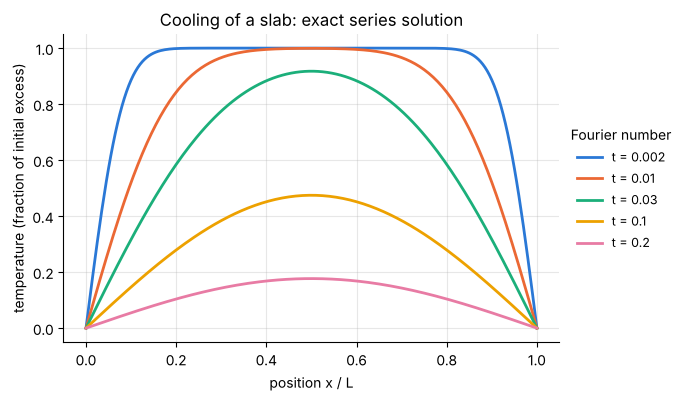

In [3]:
def u_exact(x_values, time, terms=400):
    """Series solution for the cooling slab, summed over the first `terms` odd modes."""
    k = np.arange(1, 2 * terms, 2)[:, None]
    return (4 / (k * np.pi) * np.sin(k * np.pi * x_values) * np.exp(-(k * np.pi) ** 2 * time)).sum(axis=0)

xs = np.linspace(0, 1, 201)
fig, ax = plt.subplots()
for time in (0.002, 0.01, 0.03, 0.1, 0.2):
    ax.plot(xs, u_exact(xs, time), label=f"t = {time:g}")
ax.set(xlabel="position x / L", ylabel="temperature (fraction of initial excess)", title="Cooling of a slab: exact series solution")
ax.legend(frameon=False, title="Fourier number", loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=9);

Because the modes decay as $e^{-n^2\pi^2 t}$, the higher ones vanish quickly. Heat-transfer
textbooks use a **one-term approximation** for Fourier numbers above about 0.2. How good is it
at the centre of the slab?

In [4]:
centre_one_term = sp.lambdify(t, (b_n * mode).subs({n: 1, x: sp.Rational(1, 2)}), "numpy")
for time in (0.02, 0.05, 0.1, 0.2):
    full = u_exact(np.array([0.5]), time)[0]
    print(f"t = {time:4.2f}   series {full:.5f}   one term {centre_one_term(time):.5f}   error {centre_one_term(time) / full - 1:+.2%}")
assert abs(centre_one_term(0.2) / u_exact(np.array([0.5]), 0.2)[0] - 1) < 1e-4

t = 0.02   series 0.97516   one term 1.04516   error +7.18%
t = 0.05   series 0.77231   one term 0.77731   error +0.65%
t = 0.10   series 0.47449   one term 0.47455   error +0.01%
t = 0.20   series 0.17687   one term 0.17687   error +0.00%


With this scaling (full thickness as the length), one term is within 1 % from $t = 0.05$
onwards. That corresponds to a Fourier number of 0.2 based on the half-thickness, which is the
textbook rule.

## 14.2 Finite-difference formulas, derived

A numerical method replaces derivatives by differences between values on a grid of spacing
$h$. SymPy generates the formula for any set of points.

In [5]:
h = sp.symbols("h", positive=True)
f = sp.Function("f")

central = f(x).diff(x, 2).as_finite_difference([x - h, x, x + h])
central

  2⋅f(x)   f(-h + x)   f(h + x)
- ────── + ───────── + ────────
     2         2           2   
    h         h           h    

How accurate is it? Expand the formula in a Taylor series about $x$ and see what is left over.

In [6]:
truncation = sp.simplify(sp.series(central, h, 0, 5).doit().removeO() - f(x).diff(x, 2))
truncation

   ⎛    6              4       ⎞
 2 ⎜ 2 d              d        ⎟
h ⋅⎜h ⋅───(f(x)) + 30⋅───(f(x))⎟
   ⎜     6              4      ⎟
   ⎝   dx             dx       ⎠
────────────────────────────────
              360               

The error is $\dfrac{h^2}{12} f''''(x)$ plus smaller terms: the formula is **second-order
accurate**. Halving the grid spacing divides the error by four.

`finite_diff_weights` gives the coefficients for any derivative on any set of points. Two that
are needed constantly: a one-sided first derivative for flux boundary conditions, and a
higher-order second derivative.

In [7]:
one_sided = sp.finite_diff_weights(1, [0, 1, 2], 0)[1][-1]              # d/dx at the first of three points
wide = sp.finite_diff_weights(2, [-2, -1, 0, 1, 2], 0)[2][-1]          # d2/dx2 on five points
one_sided, wide

([-3/2, 2, -1/2], [-1/12, 4/3, -5/2, 4/3, -1/12])

In [8]:
# verify the one-sided formula and its order: (-3 f0 + 4 f1 - f2) / (2h)
boundary_formula = (-3 * f(x) + 4 * f(x + h) - f(x + 2 * h)) / (2 * h)
leftover = sp.series(boundary_formula, h, 0, 3).doit().removeO() - f(x).diff(x)
assert sp.simplify(leftover + h**2 * f(x).diff(x, 3) / 3) == 0          # error is -(h²/3) f'''
sp.simplify(leftover)

     3        
  2 d         
-h ⋅───(f(x)) 
      3       
    dx        
──────────────
      3       

## 14.3 The method of lines

Discretize in space only. With $N$ intervals of width $h = 1/N$ and unknowns $u_i(t)$ at the
interior points, the heat equation becomes a system of ordinary differential equations,

$$\frac{du_i}{dt} = \frac{u_{i-1} - 2u_i + u_{i+1}}{h^2},$$

which `solve_ivp` integrates. The system is **stiff** (it contains very fast and very slow
modes), so an implicit method is used, and it is given the Jacobian, here simply the sparse
matrix of the stencil.

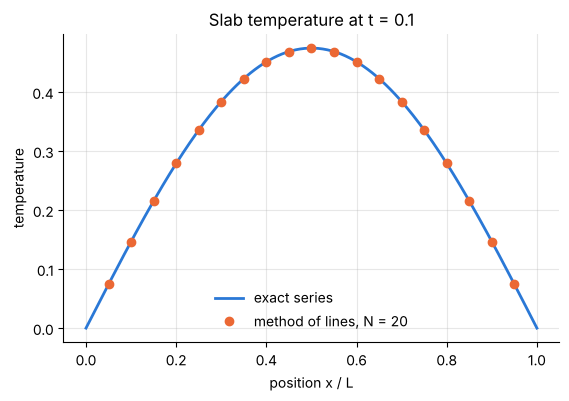

In [9]:
def solve_slab(N, t_end):
    """Method-of-lines solution of the cooling slab; returns interior points and temperatures."""
    grid = np.linspace(0, 1, N + 1)
    A = diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N - 1, N - 1), format="csc") * N**2
    sol = solve_ivp(lambda _, u: A @ u, [0, t_end], np.ones(N - 1), method="BDF", jac=A, rtol=1e-10, atol=1e-12)
    return grid[1:-1], sol.y[:, -1]

x_num, u_num = solve_slab(N=20, t_end=0.1)

fig, ax = plt.subplots()
ax.plot(xs, u_exact(xs, 0.1), label="exact series")
ax.plot(x_num, u_num, "o", color="#eb6834", ms=6, label="method of lines, N = 20")
ax.set(xlabel="position x / L", ylabel="temperature", title="Slab temperature at t = 0.1")
ax.legend(frameon=False);

**Verify the order of accuracy.** The truncation error predicted $h^2$. Refine the grid and
measure.

max error:      1.30e-04 2.41e-05 5.50e-06 1.34e-06 3.34e-07
observed order: 2.44 2.13 2.03 2.01


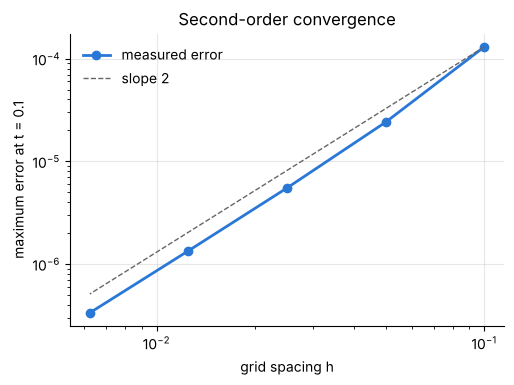

In [10]:
N_values = np.array([10, 20, 40, 80, 160])
errors = np.array([np.abs(u - u_exact(xg, 0.1)).max() for xg, u in (solve_slab(N, 0.1) for N in N_values)])
observed_order = np.log2(errors[:-1] / errors[1:])
print("max error:     ", " ".join(f"{e:.2e}" for e in errors))
print("observed order:", " ".join(f"{p:.2f}" for p in observed_order))
assert np.all(np.abs(observed_order[1:] - 2) < 0.15)

fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.loglog(1 / N_values, errors, "o-", label="measured error")
ax.loglog(1 / N_values, errors[0] * (N_values[0] / N_values) ** 2, "--", color="0.4", lw=1, label="slope 2")
ax.set(xlabel="grid spacing h", ylabel="maximum error at t = 0.1", title="Second-order convergence")
ax.legend(frameon=False);

The measured order is 2, as derived. A convergence study like this is the standard evidence
that a PDE code is correct, and it needs an exact solution to compare with, which is why 14.1
came first.

## 14.4 Why explicit time stepping blows up

The simplest scheme steps forward explicitly,
$u_j^{m+1} = u_j^m + r\,(u_{j+1}^m - 2u_j^m + u_{j-1}^m)$ with $r = \Delta t/h^2$.
It is easy to code and treacherous to use.

**By hand (von Neumann analysis).** Follow one Fourier mode of the error,
$u_j^m = g^m e^{i j\theta}$. The scheme is stable if the amplification factor satisfies
$|g| \le 1$ for every $\theta$.

In [11]:
g, r, theta = sp.symbols("g r theta", real=True)

def fourier_mode(step, node):
    return g**step * sp.exp(sp.I * node * theta)

explicit = sp.Eq(fourier_mode(1, 0), fourier_mode(0, 0) + r * (fourier_mode(0, 1) - 2 * fourier_mode(0, 0) + fourier_mode(0, -1)))
g_explicit = sp.simplify(sp.solve(explicit, g)[0].rewrite(sp.cos))
g_explicit

2⋅r⋅cos(θ) - 2⋅r + 1

In [12]:
# the same thing in the usual textbook form, and the stability limit
assert sp.simplify(g_explicit - (1 - 4 * r * sp.sin(theta / 2) ** 2)) == 0

worst = g_explicit.subs(theta, sp.pi)                     # the sawtooth mode is amplified most
r_limit = sp.solve(sp.Eq(worst, -1), r)[0]
worst, r_limit

(1 - 4⋅r, 1/2)

Stable only for $r = \Delta t/h^2 \le \tfrac12$. Halving the grid spacing forces the time step
down by a factor of four. An implicit scheme (backward Euler) has no such limit:

In [13]:
implicit = sp.Eq(fourier_mode(1, 0), fourier_mode(0, 0) + r * (fourier_mode(1, 1) - 2 * fourier_mode(1, 0) + fourier_mode(1, -1)))
g_implicit = sp.solve(implicit, g)[0]

# easier to read as 1/g: it is 1 + 4 r sin²(θ/2), never less than 1, so |g| ≤ 1 for every r
one_over_g = sp.simplify(sp.expand(1 / g_implicit).rewrite(sp.cos))
assert sp.simplify(one_over_g - (1 + 4 * r * sp.sin(theta / 2) ** 2)) == 0
one_over_g

-2⋅r⋅cos(θ) + 2⋅r + 1

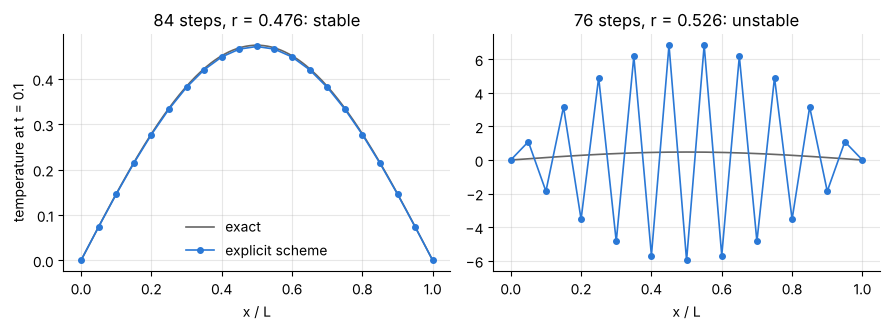

In [14]:
def explicit_march(steps, N=20, t_end=0.1):
    """March to t_end in the given number of equal steps; returns r, the grid and the result."""
    r_value = t_end * N**2 / steps
    u = np.ones(N + 1)
    u[0] = u[-1] = 0
    for _ in range(steps):
        u[1:-1] += r_value * (u[2:] - 2 * u[1:-1] + u[:-2])
    return r_value, np.linspace(0, 1, N + 1), u

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, steps in zip(axes, (84, 76)):                    # 80 steps would be exactly r = 0.5
    r_value, grid, u = explicit_march(steps)
    ax.plot(xs, u_exact(xs, 0.1), color="0.4", lw=1.2, label="exact")
    ax.plot(grid, u, "o-", ms=4, lw=1.2, label="explicit scheme")
    ax.set(xlabel="x / L", title=f"{steps} steps, r = {r_value:.3f}: {'stable' if r_value <= 0.5 else 'unstable'}")
axes[0].set_ylabel("temperature at t = 0.1")
axes[0].legend(frameon=False)
fig.tight_layout()
assert np.abs(explicit_march(84)[2]).max() < 1 and np.abs(explicit_march(76)[2]).max() > 1

A time step 5 % below the limit gives a correct answer. A time step 5 % above it gives a
sawtooth of growing amplitude, exactly the mode the analysis singled out.

## 14.5 A nonlinear problem, and how to know the code is right

**Problem.** The thermal conductivity of many materials depends on temperature. Take
$k(u) = 1 + u^2$:

$$\frac{\partial u}{\partial t} = \frac{\partial}{\partial x}\!\left[k(u)\,\frac{\partial u}{\partial x}\right].$$

No exact solution is available, so how can the program be tested?

**The method of manufactured solutions.** Choose any smooth function $u_m(x,t)$ you like.
It will not satisfy the equation, but it does satisfy the equation *with an extra source term*,
$s = \partial_t u_m - \partial_x[k(u_m)\,\partial_x u_m]$, which SymPy computes exactly. Solve
that modified problem numerically and the answer must converge to $u_m$ at the expected order.
If it does, the discretization of every term is right.

In [15]:
def conductivity(u):
    return 1 + u**2

u_m = sp.exp(-t) * sp.sin(sp.pi * x)                    # manufactured solution, zero at both walls
source = sp.simplify(u_m.diff(t) - sp.diff(conductivity(u_m) * u_m.diff(x), x))
source

⎛ 2 ⎛ 2⋅t        2         ⎞    2⋅t⎞  -3⋅t         
⎝π ⋅⎝ℯ    + 3⋅sin (π⋅x) - 2⎠ - ℯ   ⎠⋅ℯ    ⋅sin(π⋅x)

In [16]:
u_m_fun = sp.lambdify((x, t), u_m, "numpy")
source_fun = sp.lambdify((x, t), source, "numpy")

def solve_nonlinear(N, t_end, with_source=True, initial=None):
    """Conservative finite-volume form: fluxes at cell faces, conductivity at the face temperature."""
    grid = np.linspace(0, 1, N + 1)
    inner = grid[1:-1]

    def rate(time, u_inner):
        u = np.concatenate(([0.0], u_inner, [0.0]))
        k_face = conductivity((u[1:] + u[:-1]) / 2)
        flux = k_face * (u[1:] - u[:-1]) * N
        return (flux[1:] - flux[:-1]) * N + (source_fun(inner, time) if with_source else 0.0)

    start = u_m_fun(inner, 0) if initial is None else initial(inner)
    sol = solve_ivp(rate, [0, t_end], start, method="BDF", rtol=1e-10, atol=1e-12)
    return inner, sol.y[:, -1]

mms_errors = np.array([np.abs(u - u_m_fun(xg, 0.5)).max() for xg, u in (solve_nonlinear(N, 0.5) for N in (10, 20, 40, 80))])
mms_order = np.log2(mms_errors[:-1] / mms_errors[1:])
print("max error:     ", " ".join(f"{e:.2e}" for e in mms_errors))
print("observed order:", " ".join(f"{p:.2f}" for p in mms_order))
assert np.all(np.abs(mms_order - 2) < 0.1)

max error:      6.40e-03 1.59e-03 3.96e-04 9.90e-05
observed order: 2.01 2.00 2.00


Second order again: the nonlinear code is verified. Now switch the source off and use it on the
problem that has no exact solution, a slab with a sine-shaped initial temperature, comparing
constant and temperature-dependent conductivity.

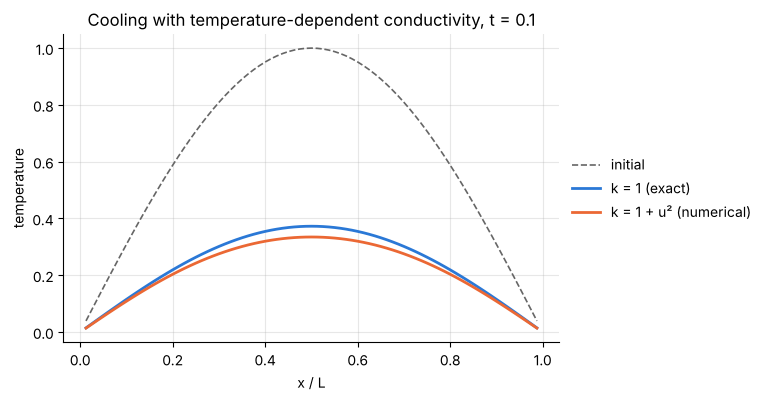

In [17]:
start_profile = lambda xv: np.sin(np.pi * xv)
x_nl, u_nl = solve_nonlinear(80, 0.1, with_source=False, initial=start_profile)
u_lin = np.exp(-np.pi**2 * 0.1) * np.sin(np.pi * x_nl)           # exact for k = 1

fig, ax = plt.subplots()
ax.plot(x_nl, start_profile(x_nl), color="0.4", lw=1.2, ls="--", label="initial")
ax.plot(x_nl, u_lin, label="k = 1 (exact)")
ax.plot(x_nl, u_nl, label="k = 1 + u² (numerical)")
ax.set(xlabel="x / L", ylabel="temperature", title="Cooling with temperature-dependent conductivity, t = 0.1")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

The material with $k = 1 + u^2$ conducts better where it is hot, so it has cooled further.

## 14.6 Two dimensions: steady conduction in a plate

**Problem.** A square plate has three edges held at $T = 0$ and the fourth ($y = 1$) at
$T = \sin(\pi x)$. Find the steady temperature, which obeys Laplace's equation
$\partial^2 T/\partial x^2 + \partial^2 T/\partial y^2 = 0$.

**Exact solution**, checked with SymPy:

In [18]:
y = sp.symbols("y", nonnegative=True)
T_exact = sp.sin(sp.pi * x) * sp.sinh(sp.pi * y) / sp.sinh(sp.pi)

assert sp.simplify(T_exact.diff(x, 2) + T_exact.diff(y, 2)) == 0
assert T_exact.subs(y, 0) == 0 and T_exact.subs(x, 0) == 0 and T_exact.subs(x, 1) == 0
assert sp.simplify(T_exact.subs(y, 1) - sp.sin(sp.pi * x)) == 0
T_exact_fun = sp.lambdify((x, y), T_exact, "numpy")

**Numerically**, the five-point stencil (the three-point formula of 14.2 applied in both
directions: a node and its four neighbours) turns the
PDE into one large sparse linear system. With $N = 80$ there are 6241 unknowns and the matrix
has 39 million entries, of which only about 31 thousand are non-zero. Sparse storage is what
makes this practical.

In [19]:
def solve_plate(N):
    second_difference = diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(N - 1, N - 1))
    eye = identity(N - 1)
    laplacian = (kron(eye, second_difference) + kron(second_difference, eye)).tocsc()     # rows: y, columns: x
    inner = np.linspace(0, 1, N + 1)[1:-1]
    rhs = np.zeros((N - 1, N - 1))
    rhs[-1, :] = -np.sin(np.pi * inner)                    # the known hot edge moves to the right-hand side
    X, Y = np.meshgrid(inner, inner)
    return X, Y, spsolve(laplacian, rhs.ravel()).reshape(N - 1, N - 1), laplacian

plate_errors = []
for N in (20, 40, 80):
    X, Y, T_num, laplacian = solve_plate(N)
    plate_errors.append(np.abs(T_num - T_exact_fun(X, Y)).max())
plate_order = np.log2(np.array(plate_errors[:-1]) / np.array(plate_errors[1:]))
print(f"N = 80: {laplacian.shape[0]} unknowns, {laplacian.nnz} non-zero matrix entries")
print("max error:     ", " ".join(f"{e:.2e}" for e in plate_errors))
print("observed order:", " ".join(f"{p:.2f}" for p in plate_order))
assert np.all(np.abs(plate_order - 2) < 0.05)

N = 80: 6241 unknowns, 30889 non-zero matrix entries
max error:      7.11e-04 1.78e-04 4.46e-05
observed order: 2.00 2.00


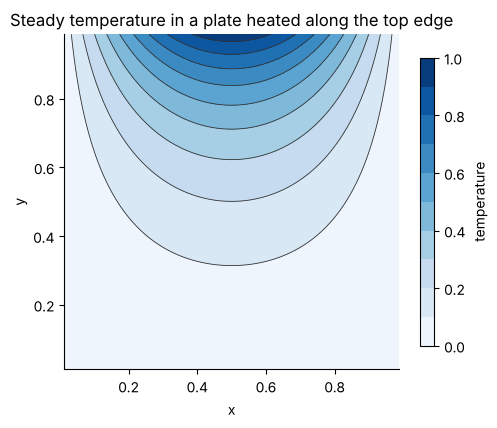

In [20]:
fig, ax = plt.subplots(figsize=(5.4, 4.4))
filled = ax.contourf(X, Y, T_num, levels=np.linspace(0, 1, 11), cmap="Blues")
ax.contour(X, Y, T_num, levels=np.linspace(0.1, 0.9, 9), colors="0.2", linewidths=0.6)
ax.set(xlabel="x", ylabel="y", title="Steady temperature in a plate heated along the top edge", aspect="equal")
ax.grid(False)
fig.colorbar(filled, ax=ax, label="temperature", shrink=0.85);

## Where to go from here

The pattern of this notebook, **exact solution → stencil → stability → convergence study**,
carries over to any PDE. For real geometries and coupled physics, use a dedicated package
instead of writing stencils by hand:

| Package | Method | Good for |
| --- | --- | --- |
| [py-pde](https://py-pde.readthedocs.io) | finite differences | reaction–diffusion and pattern formation on simple grids |
| [FiPy](https://www.ctcms.nist.gov/fipy/) | finite volumes | transport and phase-field problems |
| [FEniCSx](https://fenicsproject.org) | finite elements | complex geometry, solid mechanics, multiphysics |

Whatever the package, the method of manufactured solutions from 14.5 remains the way to check
that your set-up is right, and SymPy remains the tool for producing the source term.

## Exercises

1. Use the five-point weights of 14.2 to write a fourth-order formula for $f''(x)$, and find
   the leading term of its truncation error. (It should be $-\dfrac{h^4}{90} f^{(6)}(x)$.)
2. Change the slab so that the face at $x = 1$ is insulated, $\partial u/\partial x = 0$, and
   solve it by the method of lines for $t = 0.1$. Treat the wall value $u_N$ as an unknown and
   use a mirror ("ghost") point, $u_{N+1} = u_{N-1}$. Check the result against the exact series
   for a slab of thickness 2 cooled on both faces, which is the same problem by symmetry.
3. The Crank–Nicolson scheme averages the explicit and implicit right-hand sides. Derive its
   amplification factor and show that $|g| \le 1$ for every $r$.
4. A fin loses heat from its surface: $\dfrac{\partial\theta}{\partial t} =
   \dfrac{\partial^2\theta}{\partial x^2} - m^2\theta$ with $\theta(0,t) = 1$, an insulated tip
   at $x = 1$, $\theta(x,0) = 0$ and $m = 2$. Integrate to $t = 3$ and show that the solution has
   reached the steady profile $\cosh m(1-x)/\cosh m$ of notebook 6.
5. Verify a method-of-lines code for the viscous Burgers equation
   $\dfrac{\partial u}{\partial t} + u\dfrac{\partial u}{\partial x} = \nu\dfrac{\partial^2 u}{\partial x^2}$
   with $\nu = 0.1$, using the manufactured solution $u_m = e^{-t}\sin(\pi x)$ and central
   differences. Confirm second-order convergence.